In [33]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import sys
from pathlib import Path

In [34]:
# Add the project root (parent of notebooks/) to sys.path
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.pipeline import NYCTaxiPipeline

pipe = NYCTaxiPipeline()
train_df, test_df = pipe.split()

train_ready = pipe.fit_transform(train_df)
test_ready = pipe.transform(test_df)

In [35]:
# 1. Build the 263 Zones x 24 Hours Demand Profile Matrix
# We aggregate the training data to find the average trip count per zone for each hour of the day (0 to 23).
profile_df = (
    train_df.groupby(["zone_id", "hour"])["trip_count"]
    .mean()
    .unstack(level="hour")  # Shape: (263 zones, 24 hours)
    .fillna(0)
)

# Extract feature matrix X and zone IDs
zone_ids = profile_df.index.values
X_profiles = profile_df.values

# 2. Standardize the Demand Profiles
# This ensures that high-volume zones (like Midtown) and low-volume zones 
# are compared based on their temporal *shape* rather than absolute magnitude.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_profiles)

In [36]:
# 3. Evaluate K-Means Across Different Values of k Using Silhouette Score
k_range = range(3, 9)  # Testing k from 3 to 8
silhouette_scores = []
inertias = []

print("Evaluating K-Means cluster configurations...")
for k in k_range:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  cluster_labels = kmeans.fit_predict(X_scaled)

  # Compute Silhouette Score (higher is better, measures cluster separation & cohesion)
  score = silhouette_score(X_scaled, cluster_labels)
  silhouette_scores.append(score)
  inertias.append(kmeans.inertia_)
  print(f" > k = {k} | Silhouette Score: {score:.4f}")

Evaluating K-Means cluster configurations...
 > k = 3 | Silhouette Score: 0.8088
 > k = 4 | Silhouette Score: 0.8022
 > k = 5 | Silhouette Score: 0.7966
 > k = 6 | Silhouette Score: 0.7997
 > k = 7 | Silhouette Score: 0.7799
 > k = 8 | Silhouette Score: 0.7426


In [37]:
# 4. Select Optimal k
optimal_k = k_range[np.argmax(silhouette_scores)]
print(
    f"\n✨ Optimal k chosen by highest Silhouette Score: k = {optimal_k}"
)

# optimal_k = 6

# 5. Fit Final Optimal K-Means Model
optimal_kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
final_labels = optimal_kmeans.fit_predict(X_scaled)

# Map cluster labels back to zones
zone_clusters = pd.DataFrame(
    {"zone_id": zone_ids, "cluster_id": final_labels}
).set_index("zone_id")


✨ Optimal k chosen by highest Silhouette Score: k = 3


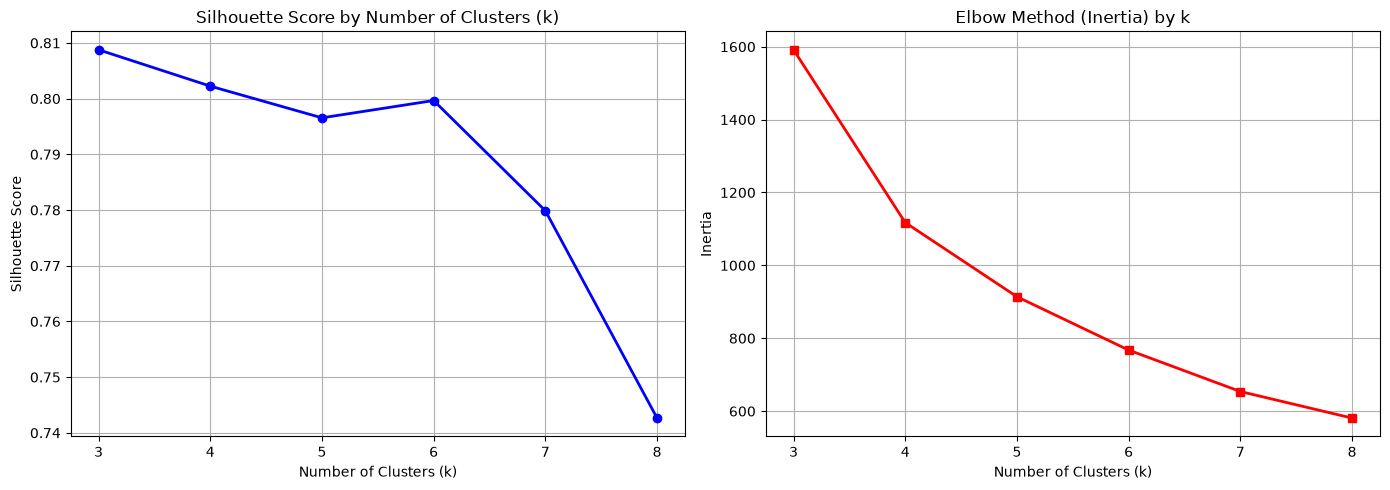

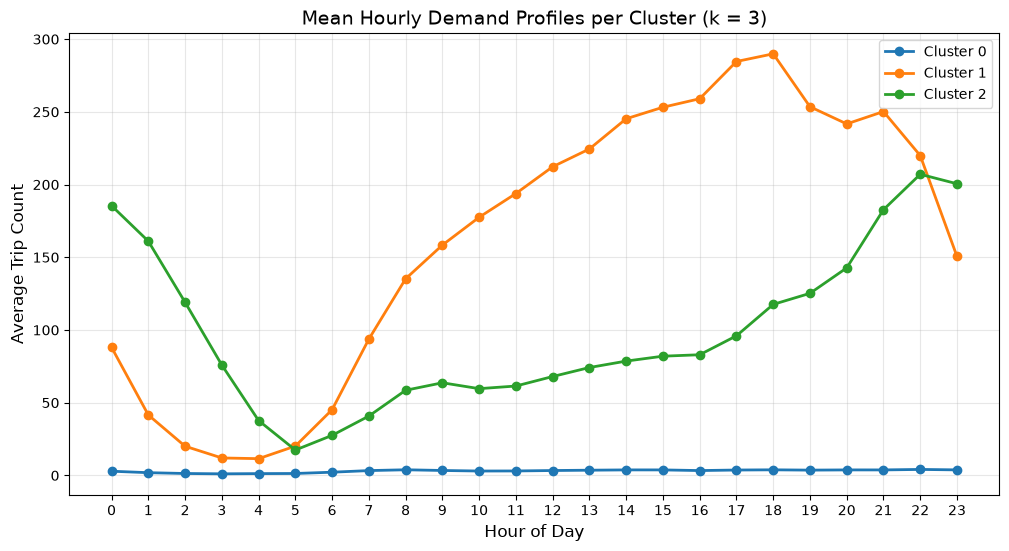

In [38]:
# Plot Silhouette Scores & Inertia Elbow
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_range, silhouette_scores, marker="o", color="b", lw=2)
axes[0].set_title("Silhouette Score by Number of Clusters (k)")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Silhouette Score")
axes[0].grid(True)

axes[1].plot(k_range, inertias, marker="s", color="r", lw=2)
axes[1].set_title("Elbow Method (Inertia) by k")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Inertia")
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Plot Mean Hourly Demand Profiles for Each Cluster
profile_df["cluster"] = final_labels
cluster_profiles = profile_df.groupby("cluster").mean()

plt.figure(figsize=(12, 6))
for cluster_id in range(optimal_k):
  plt.plot(
      range(24),
      cluster_profiles.loc[cluster_id, range(24)],
      marker="o",
      linewidth=2,
      label=f"Cluster {cluster_id}",
  )

plt.title(
    f"Mean Hourly Demand Profiles per Cluster (k = {optimal_k})", fontsize=14
)
plt.xlabel("Hour of Day", fontsize=12)
plt.ylabel("Average Trip Count", fontsize=12)
plt.xticks(range(24))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

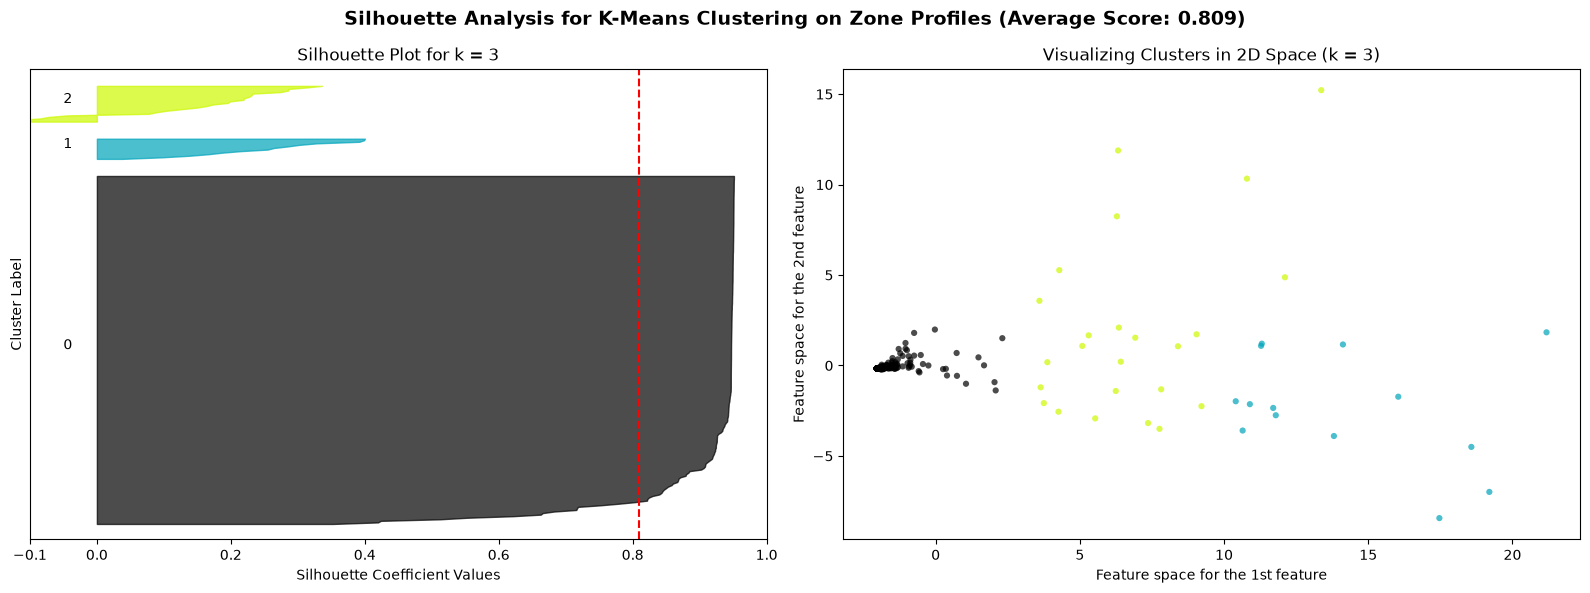

In [39]:
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import silhouette_samples, silhouette_score

# Ensure you have already defined optimal_k and X_scaled from your clustering step
# e.g., optimal_k = 4 (or whatever your best k was)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# 1. Silhouette Plot (Left Subplot)
ax1.set_xlim([-0.1, 1.0])
# (n_clusters + 1)*10 gives space between silhouette plots for different clusters
ax1.set_ylim([0, len(X_scaled) + (optimal_k + 1) * 10])

kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)

# Calculate average silhouette score for the whole plot
silhouette_avg = silhouette_score(X_scaled, cluster_labels)
sample_silhouette_values = silhouette_samples(X_scaled, cluster_labels)

y_lower = 10
for i in range(optimal_k):
  # Aggregate silhouette scores for samples belonging to cluster i, and sort them
  ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]
  ith_cluster_silhouette_values.sort()

  size_cluster_i = ith_cluster_silhouette_values.shape[0]
  y_upper = y_lower + size_cluster_i

  color = cm.nipy_spectral(float(i) / optimal_k)
  ax1.fill_betweenx(
      np.arange(y_lower, y_upper),
      0,
      ith_cluster_silhouette_values,
      facecolor=color,
      edgecolor=color,
      alpha=0.7,
  )

  # Label the silhouette plots with their cluster numbers at the middle
  ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

  # Compute new y_lower for next cluster plot
  y_lower = y_upper + 10  # 10 for the 0 samples

ax1.set_title(f"Silhouette Plot for k = {optimal_k}")
ax1.set_xlabel("Silhouette Coefficient Values")
ax1.set_ylabel("Cluster Label")

# The vertical line for average silhouette score of all the values
ax1.axvline(x=silhouette_avg, color="red", linestyle="--")
ax1.set_yticks([])  # Clear the y-axis labels / ticks
ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1.0])

# 2. PCA Scatter Plot (Right Subplot - for visual reference alongside the diagram)
pca = PCA(n_components=2, random_state=60)
X_pca = pca.fit_transform(X_scaled)
colors = cm.nipy_spectral(cluster_labels.astype(float) / optimal_k)

ax2.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    marker=".",
    s=80,
    lw=0,
    alpha=0.7,
    c=colors,
    edgecolor="k",
)

# Plot cluster centers if needed, or keep clean
ax2.set_title(f"Visualizing Clusters in 2D Space (k = {optimal_k})")
ax2.set_xlabel("Feature space for the 1st feature")
ax2.set_ylabel("Feature space for the 2nd feature")

plt.suptitle(
    f"Silhouette Analysis for K-Means Clustering on Zone Profiles (Average Score:"
    f" {silhouette_avg:.3f})",
    fontsize=14,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

In [40]:
import pandas as pd

# Load the official NYC TLC taxi zone lookup file
# (Adjust the path if your CSV is stored in a subfolder like 'data/taxi_zone_lookup.csv')
lookup_df = pd.read_csv("../data/spatial/taxi_zone_lookup.csv")

# Ensure the ID column matches your dataframe's zone_id format (usually 'LocationID')
# Sometimes the column is named 'LocationID' in the official TLC dataset.

# 1. Extract zone metadata and merge with the lookup table for descriptive names
zone_meta = (
    train_df[["zone_id", "Borough", "service_zone"]]
    .drop_duplicates()
    .set_index("zone_id")
)

# Map the exact Zone names using LocationID as the key
zone_meta["Zone"] = lookup_df.set_index("LocationID")["Zone"]

# 2. Combine cluster labels with zone metadata and average hourly demand
cluster_summary_df = zone_meta.copy()
cluster_summary_df["cluster"] = profile_df["cluster"]
cluster_summary_df["avg_hourly_trips"] = profile_df[range(24)].mean(axis=1)

# 3. Print a structured breakdown of the zones in each cluster
for cluster_id in sorted(cluster_summary_df["cluster"].unique()):
  subset = cluster_summary_df[
      cluster_summary_df["cluster"] == cluster_id
  ].sort_values(by="avg_hourly_trips", ascending=False)

  print(f"{'='*60}")
  print(
      f"CLUSTER {cluster_id} | Total Zones: {len(subset)} | Mean Demand:"
      f" {subset['avg_hourly_trips'].mean():.1f} trips/hr"
  )
  print(f"Borough Breakdown: {subset['Borough'].value_counts().to_dict()}")
  print(f"{'-'*60}")

  # Display top 15 busiest zones including their neighborhood/zone names
  display(subset[["Zone", "Borough", "service_zone", "avg_hourly_trips"]].head(15))
  print("\n")

CLUSTER 0 | Total Zones: 222 | Mean Demand: 3.1 trips/hr
Borough Breakdown: {'Queens': 67, 'Brooklyn': 61, 'Bronx': 43, 'Manhattan': 30, 'Staten Island': 20, 'EWR': 1}
------------------------------------------------------------


,Zone,Borough,service_zone,avg_hourly_trips
zone_id,,,,
87,Financial District North,Manhattan,Yellow Zone,34.034305
50,Clinton West,Manhattan,Yellow Zone,32.806548
13,Battery Park City,Manhattan,Yellow Zone,31.693296
166,Morningside Heights,Manhattan,Boro Zone,26.588816
125,Hudson Sq,Manhattan,Yellow Zone,25.568452
261,World Trade Center,Manhattan,Yellow Zone,25.402569
41,Central Harlem,Manhattan,Boro Zone,19.888001
74,East Harlem North,Manhattan,Boro Zone,18.210213
88,Financial District South,Manhattan,Yellow Zone,16.517074




CLUSTER 1 | Total Zones: 14 | Mean Demand: 161.8 trips/hr
Borough Breakdown: {'Manhattan': 12, 'Queens': 2}
------------------------------------------------------------


,Zone,Borough,service_zone,avg_hourly_trips
zone_id,,,,
161,Midtown Center,Manhattan,Yellow Zone,221.378289
237,Upper East Side South,Manhattan,Yellow Zone,220.788690
132,JFK Airport,Queens,Airports,213.226034
236,Upper East Side North,Manhattan,Yellow Zone,192.673872
186,Penn Station/Madison Sq West,Manhattan,Yellow Zone,163.617638
162,Midtown East,Manhattan,Yellow Zone,159.509555
230,Times Sq/Theatre District,Manhattan,Yellow Zone,159.279292
142,Lincoln Square East,Manhattan,Yellow Zone,141.394737
138,LaGuardia Airport,Queens,Airports,137.653822




CLUSTER 2 | Total Zones: 5 | Mean Demand: 98.6 trips/hr
Borough Breakdown: {'Manhattan': 5}
------------------------------------------------------------


,Zone,Borough,service_zone,avg_hourly_trips
zone_id,,,,
79,East Village,Manhattan,Yellow Zone,125.063596
48,Clinton East,Manhattan,Yellow Zone,119.572055
249,West Village,Manhattan,Yellow Zone,112.348997
114,Greenwich Village South,Manhattan,Yellow Zone,74.063910
148,Lower East Side,Manhattan,Yellow Zone,61.902569




CLUSTER 3 | Total Zones: 22 | Mean Demand: 70.5 trips/hr
Borough Breakdown: {'Manhattan': 22}
------------------------------------------------------------


,Zone,Borough,service_zone,avg_hourly_trips
zone_id,,,,
164,Midtown South,Manhattan,Yellow Zone,107.443296
141,Lenox Hill West,Manhattan,Yellow Zone,106.008302
107,Gramercy,Manhattan,Yellow Zone,95.032895
140,Lenox Hill East,Manhattan,Yellow Zone,94.208177
246,West Chelsea/Hudson Yards,Manhattan,Yellow Zone,90.567982
263,Yorkville West,Manhattan,Yellow Zone,87.333020
238,Upper West Side North,Manhattan,Yellow Zone,87.303571
229,Sutton Place/Turtle Bay North,Manhattan,Yellow Zone,78.624843
90,Flatiron,Manhattan,Yellow Zone,77.105890
